<a href="https://colab.research.google.com/github/seisbench/seisbench/blob/additional_example_workflows/examples/02d_polarities.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![image](https://raw.githubusercontent.com/seisbench/seisbench/main/docs/_static/seisbench_logo_subtitle_outlined.svg)

*This code is necessary on colab to install SeisBench. If SeisBench is already installed on your machine, you can skip this.*

In [ ]:
!pip install seisbench

This cell is required to circumvent an issue with colab and obspy. For details, check this issue in the obspy documentation: https://github.com/obspy/obspy/issues/2547

In [ ]:
try:
    import obspy

    obspy.read()
except TypeError:
    # Needs to restart the runtime once, because obspy only works properly after restart.
    print(
        "Stopping RUNTIME. If you run this code for the first time, this is expected. Colaboratory will restart automatically. Please run again."
    )
    exit()

# Picking first motion polarities

This tutorial shows how to use deep learning models to determine first motion polarities. In this tutorial, we will use the models EquiPol (Kartseva et al., 2026) and RPNet (Han et al., 2025).

*Note:* For this tutorial, we assume you're already familiar with the basics of SeisBench models.

In [2]:
import seisbench.models as sbm

import matplotlib.pyplot as plt
import numpy as np
import obspy
from obspy.clients.fdsn import Client
from obspy.clients.fdsn.header import FDSNNoDataException
from obspy import UTCDateTime

## Inspecting the data

As an example, we will look at a M=3.1 earthquake in California (https://earthquake.usgs.gov/earthquakes/eventpage/ci41344007/executive). We will download data from the SCEDC.

In [3]:
client = Client("SCEDC")
t0 = UTCDateTime("2026-10-06 09:37:56")
lat0 = 35.684
lon0 = -118.411

Let's start with the waveforms of a nearby station. Given we are looking at polarities, we can focus on the vertical component. Both P and S arrival of the event are clearly visible on the station.

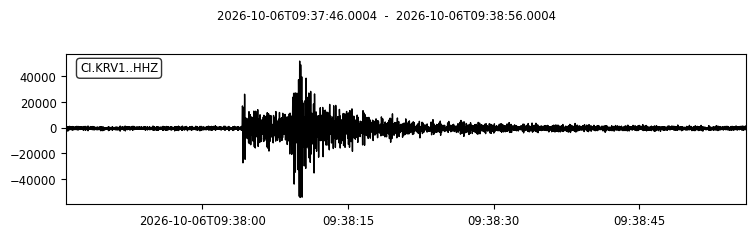

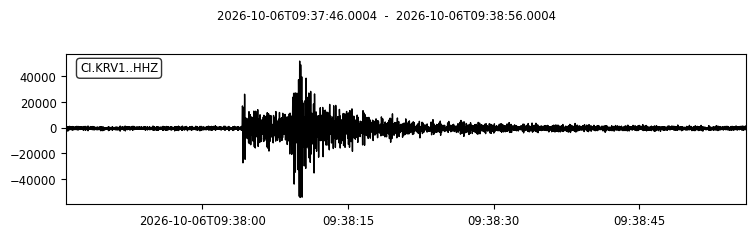

In [4]:
stream = client.get_waveforms(
    network="CI",
    station="KRV1",
    location="",
    channel="HHZ",
    starttime=t0 - 10,
    endtime=t0 + 60,
)

stream.plot()

Let's have a closer look at the P onset. In this case, the impulsive arrival shows a clear upward polarity.

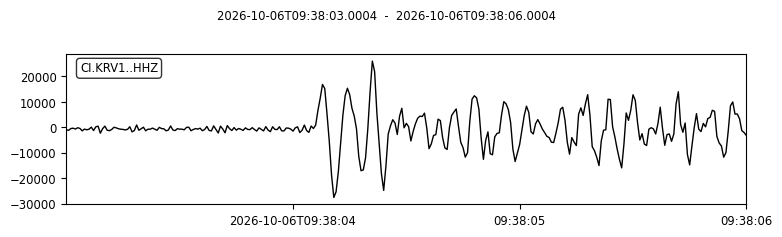

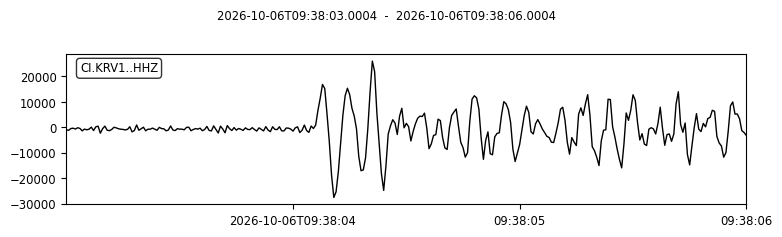

In [5]:
stream.slice(t0 + 7, t0 + 10).plot()

## Automatic polarity picking

For automatic polarity picking, SeisBench offers different models. Here we'll try out two of them. As for all other SeisBench models, we can load pretrained weights with `from_pretrained`. Try out the following steps with both models. Both of them have been trained on a combination of six different datasets to give them good generalization abilities.

In [6]:
polarity_model = sbm.EquiPol.from_pretrained("tepicc_Z")
# polarity_model = sbm.RPNet.from_pretrained("tepicc")

In contrast to a picking model that goes through the whole waveform, the polarity model needs to be told explicitly where to identify the polarity. Below, we define the pick to use. Each pick is defined as a tuple. First, a station code in the form `NET.STA.LOC`. Second, the time of the pick. Don't worry if it's not totally accurate, the models have been trained to deal with picking errors.

In [7]:
picks = [("CI.KRV1.", UTCDateTime("2026-10-06T09:38:04.1"))]

Now we can run the model. There are two available functions. First, annotate gives us raw probabilities for down and up polarity.

In [9]:
polarity_model.annotate(stream, picks=picks)

[array([0.00485848, 0.9951415 ], dtype=float32)]

The model identifies with high confidence that the pick has an up polarity. Note that the two probabilities sum to 1.

The second interface, classify, gives us picks as python objects. This give us useful methods, like conversion to pandas data frames.

In [10]:
polarities = polarity_model.classify(stream, picks=picks).picks
print(polarities[0])

CI.KRV1.	2026-10-06T09:38:04.100000Z	U


Often, it can be cumbersome to provide manual P picks. Instead, we can also use a picking model like PhaseNet. SeisBench allows us to directly pass the output of PhaseNet to the polarity models. Note that PhaseNet automatically identified both P and S picks in the trace. The polarity model only runs on the P picks, while the S picks are quitely passed through.

In [13]:
picker = sbm.PhaseNet.from_pretrained("original")

picks = picker.classify(stream, P_threshold=0.1, S_threshold=0.1).picks
polarities = polarity_model.classify(stream, picks=picks, threshold=0.8).picks

polarities.to_dataframe()

,index,station,time,start_time,end_time,probability,phase,polarity,polarity_probability
0,0,CI.KRV1.,2026-10-06 09:38:04.110400,2026-10-06 09:38:03.920400,2026-10-06 09:38:04.330400,0.978398,P,U,0.997057
1,1,CI.KRV1.,2026-10-06 09:38:09.250400,2026-10-06 09:38:09.000400,2026-10-06 09:38:09.580400,0.690929,S,NaN,NaN


## Picking a full event

So far, we've looked only at an individual trace. However, SeisBench can also process a larger number of picks at once, for example, a whole event. Sticking with the event from above, let's have a look at a larger number of stations. First, we identify all available stations in the CI network within 1 degree of the event. Given we're looking at California, there's a good number.

In [14]:
inv = client.get_stations(
    network="CI",
    latitude=lat0,
    longitude=lon0,
    minradius=0,
    maxradius=1.0,
    startbefore=t0,
    endafter=t0,
)
inv

Inventory created at 2026-11-05T13:59:19.000000Z
	Created by: SCEDC WEB SERVICE: fdsnws-station | version: 1.1
		    http://service.scedc.caltech.edu/fdsnws/station/1/query?net=CI&star...
	Sending institution: SCEDC (SCEDC)
	Contains:
		Networks (1):
			CI
		Stations (62):
			CI.ARV (Arvin)
			CI.ASP (Allensworth State Park)
			CI.BAI (Bailey)
			CI.BAK (Calstate Bakersfield)
			CI.CCA (California City Airport)
			CI.CCC (Christmas Canyon China Lake)
			CI.CGO (Cerro Gordo)
			CI.CLC (China Lake)
			CI.CVW (Castaic Valley West)
			CI.CWC (Cottonwood Creek)
			CI.DAW (Darwin)
			CI.DTP (Desert Tortoise Park)
			CI.EDW2 (Edwards 2)
			CI.FDR (5 Dogs Range)
			CI.FOX2 (Fox Airport 2)
			CI.FSR (Fish Rocks)
			CI.HDH (High Desert Hunt Club - Tejon Ranch)
			CI.ISA (Isabella)
			CI.JRC2 (Joshua Ridge: China Lake)
			CI.KRV1 (Kern River P P #1)
			CI.KRV3 (Kern River P P #3)
			CI.LDR (Leduc Ranch)
			CI.LJR (Lone Juniper Ranch)
			CI.LMR2 (Leuhmann Ridge Extension)
			CI.LRL (Laurel Mtn)
		

Now let's download the waveforms around the event. This might take a moment and not all stations will have available waveforms.

In [15]:
stream = obspy.Stream()
for net in inv:
    for sta in net:
        try:
            stream += client.get_waveforms(
                network=net.code,
                station=sta.code,
                location="*",
                channel="HHZ",
                starttime=t0 - 10,
                endtime=t0 + 60,
            )
            print(net.code, sta.code, "has data")
        except FDSNNoDataException:
            print(net.code, sta.code, "-")
            continue

CI ARV has data
CI ASP -
CI BAI has data
CI BAK has data
CI CCA has data
CI CCC has data
CI CGO has data
CI CLC -
CI CVW has data
CI CWC has data
CI DAW has data
CI DTP has data
CI EDW2 has data
CI FDR has data
CI FOX2 has data
CI FSR has data
CI HDH has data
CI ISA has data
CI JRC2 has data
CI KRV1 has data
CI KRV3 has data
CI LDR -
CI LJR has data
CI LMR2 has data
CI LRL has data
CI MAG -
CI MPM has data
CI NEN has data
CI POP has data
CI POR has data
CI Q0024 -
CI Q0065 -
CI Q0068 -
CI Q0072 -
CI RRC has data
CI SEV has data
CI SHR has data
CI SLA has data
CI SPG2 has data
CI SRT has data
CI TEH has data
CI TEJ has data
CI TER2 has data
CI TFT has data
CI THC -
CI TJR has data
CI TOW2 has data
CI TPO has data
CI VES has data
CI WAS2 has data
CI WBM -
CI WBP has data
CI WBS -
CI WCS2 has data
CI WHF has data
CI WLH2 has data
CI WMF has data
CI WNM -
CI WOR has data
CI WRC2 has data
CI WRV2 -
CI WVP2 has data


Let's apply the model. As before, we use PhaseNet to identify the picks and the polarity model for determining the polarities. For this example, we are not interested in S picks, so we simply set the S_threshold to 1. For the polarity, we set a threshold of 0.8, i.e., SeisBench won't report any polarities with lower confidence.

*Note:* SeisBench automatically cuts the right segements from the stream based on the provided picks. If you provide a pick without fitting waveforms in the stream, no polarity is reported for this pick.

In [17]:
picks = picker.classify(stream, P_threshold=0.1, S_threshold=1.0).picks
picks = polarity_model.classify(stream, picks=picks, threshold=0.8).picks

We've obtained a large number of picks with high confidence polarities. If you look through the list, you'll also find our initial example (CI.KRV1).

In [18]:
picks.to_dataframe()

,index,station,time,start_time,end_time,probability,phase,polarity,polarity_probability
0,15,CI.ISA.,2026-10-06 09:37:58.530400,2026-10-06 09:37:58.450400,2026-10-06 09:37:58.750400,0.284368,P,D,0.983796
1,18,CI.KRV3.,2026-10-06 09:37:58.990400,2026-10-06 09:37:58.800400,2026-10-06 09:37:59.200400,0.879551,P,U,0.965622
2,41,CI.WAS2.,2026-10-06 09:37:59.948300,2026-10-06 09:37:59.798300,2026-10-06 09:38:00.138300,0.324390,P,U,0.992485
3,42,CI.WBP.,2026-10-06 09:38:03.350400,2026-10-06 09:38:03.250400,2026-10-06 09:38:03.600400,0.280778,P,U,0.995312
4,17,CI.KRV1.,2026-10-06 09:38:04.110400,2026-10-06 09:38:03.920400,2026-10-06 09:38:04.330400,0.978398,P,U,0.997057
5,33,CI.TEH.,2026-10-06 09:38:04.308300,2026-10-06 09:38:04.158300,2026-10-06 09:38:04.528300,0.631394,P,D,0.996066
6,11,CI.FDR.,2026-10-06 09:38:05.243100,2026-10-06 09:38:04.963100,2026-10-06 09:38:05.523100,0.671479,P,NaN,NaN
7,27,CI.RRC.,2026-10-06 09:38:05.790400,2026-10-06 09:38:05.600400,2026-10-06 09:38:06.020400,0.979540,P,U,0.996173
8,44,CI.WLH2.,2026-10-06 09:38:05.990400,2026-10-06 09:38:05.830400,2026-10-06 09:38:06.180400,0.516502,P,U,0.972229
9,34,CI.TEJ.,2026-10-06 09:38:06.440400,2026-10-06 09:38:06.250400,2026-10-06 09:38:06.660400,0.838944,P,U,0.986547


With just a list, it's hard to fully grasp the polarities. Below, we plot the spatial distribution of up (red) and down (blue) polarities. Grey triangles show stations where no polarity could be determined. You might notice the clear spatial patterns. If you check the focal mechanism solution on the USGS site, it is overall consistent with our polarities.

*Note:* To avoid a dependency on cartopy, we simply plot latitude and longitude for each station. This leads to some distortion, but hopefully still conveys the key point.

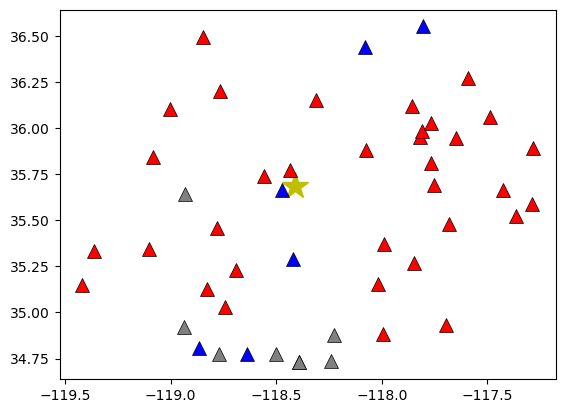

In [19]:
fig = plt.figure()
ax = fig.add_subplot(111)

ax.plot(lon0, lat0, "y*", ms=20)

polarity_colors = {
    "U": "r",
    "D": "b",
    np.nan: "grey",
}

for row in picks.to_dataframe().itertuples():
    # ax.plot(sta.longitude, sta.latitude, "k^")
    inv.get_coordinates
    net, sta, loc = row.station.split(".")
    sta = inv.select(network=net, station=sta, location=loc)[0][0]

    ax.plot(
        sta.longitude,
        sta.latitude,
        "^",
        ms=10,
        mew=0.5,
        mec="k",
        c=polarity_colors[row.polarity],
    )

## Closing remarks

In this tutorial, you've learned how to use SeisBench for automatic polarity determination. The resulting polarities can be provided directly to focal mechanisms inversion tools like SKHASH.